# Fase 2 — Entendimento da venda observada

**Somente train: 28/03 a 25/06/2024. Eval permanece congelado.**

Venda normalizada não equivale a demanda latente nem a unidades físicas. Este notebook contém nove figuras e consome apenas os outputs do script `python scripts/build_demand_profile.py`. Fórmulas e seleção de exemplos ficam em SQL/src; não há transformação crítica exclusiva aqui. Consulte `docs/demand_understanding_report.md` para tabelas completas e `docs/methodology.md` para definições.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'src').is_dir():
    root = root.parent
sys.path.insert(0, str(root))
import matplotlib.pyplot as plt
from IPython.display import display
from src.reporting.demand_understanding_plots import load_outputs, PLOTS, save_figure
data = load_outputs(root)
assert data['summary']['source_split'] == 'train'
print(f"{data['summary']['overview']['n_series']:,} séries; fonte: {data['summary']['source']['path']}")

50,000 séries; fonte: data/raw/train.parquet


## 01. Nível e variabilidade

A distribuição de médias é assimétrica. CV é descritivo e mistura disponibilidade, promoção e variação de venda.

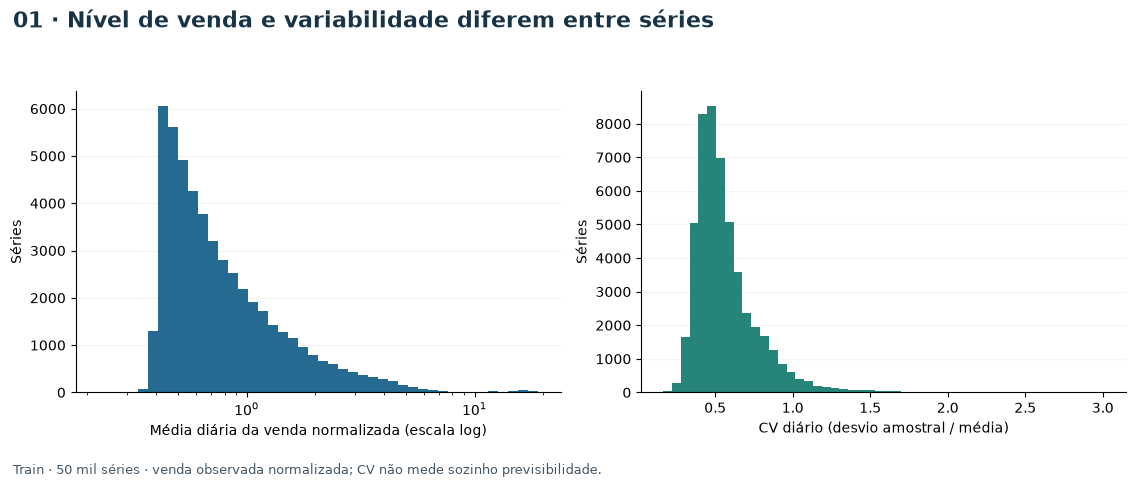

In [2]:
fig = PLOTS[0](data)
save_figure(fig, 1, root)
display(fig)
plt.close(fig)

## 02. Concentração

Compare a participação de produtos, lojas e pares loja-produto. A linha de 80% é referência de leitura; nenhuma classe ABC foi atribuída.

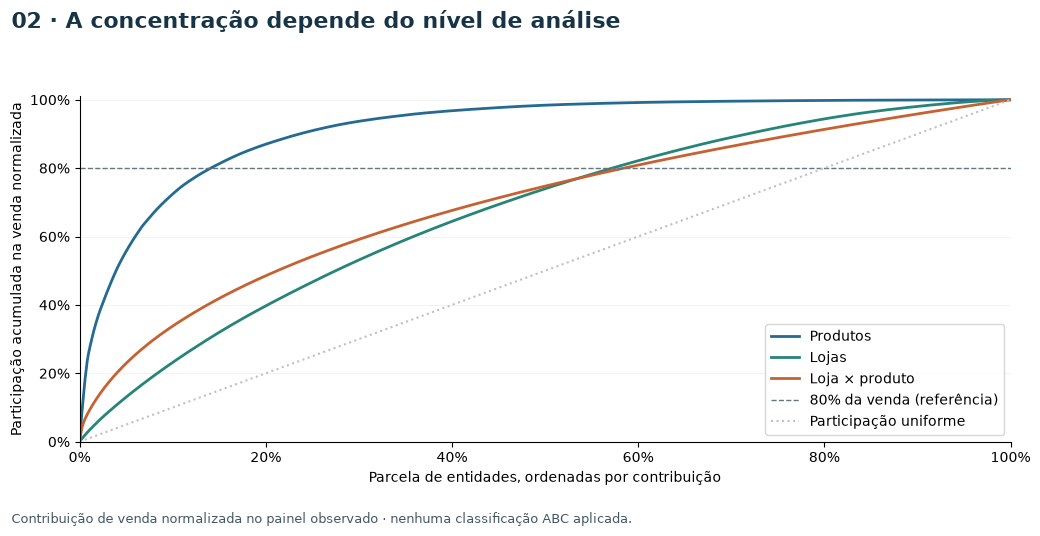

In [3]:
fig = PLOTS[1](data)
save_figure(fig, 2, root)
display(fig)
plt.close(fig)

## 03. Zeros e ADI

Observe toda a distribuição. ADI e zero_ratio são redundantes nesta janela completa; zeros podem coincidir com ruptura.

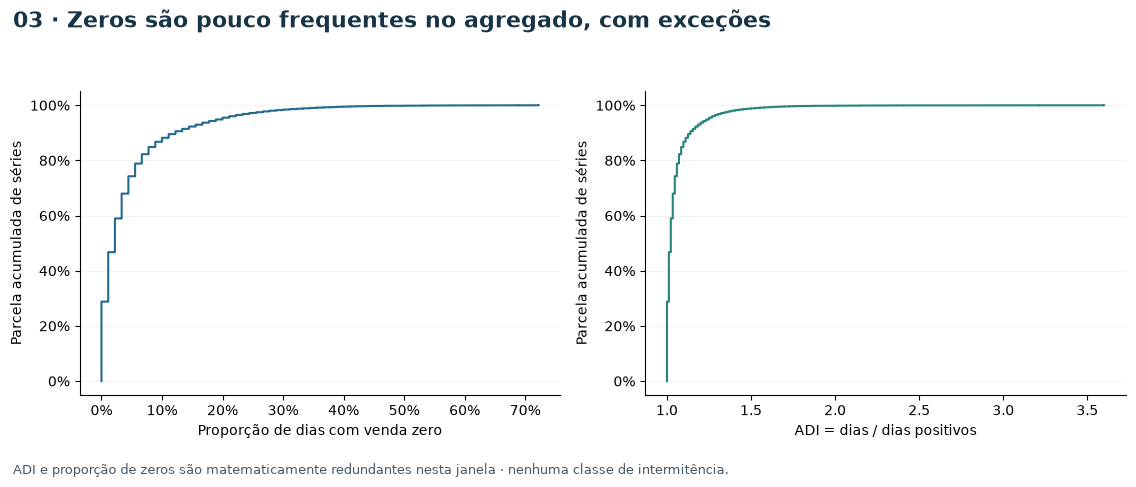

In [4]:
fig = PLOTS[2](data)
save_figure(fig, 3, root)
display(fig)
plt.close(fig)

## 04. Perfil por dia da semana

Médias por observação corrigem a contagem desigual de weekdays. A faixa relativa mostra diferenças entre séries, sem teste causal.

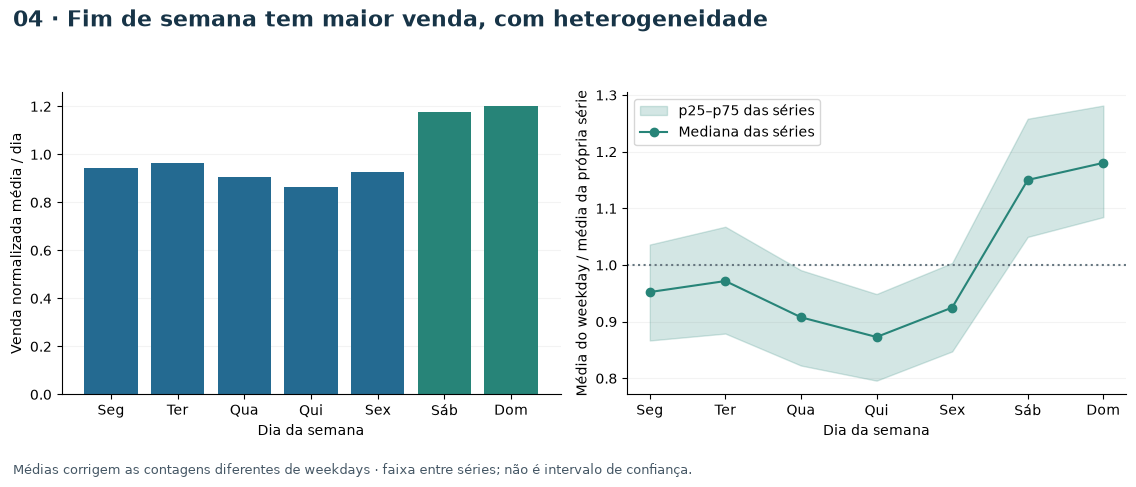

In [5]:
fig = PLOTS[3](data)
save_figure(fig, 4, root)
display(fig)
plt.close(fig)

## 05. Estabilidade semanal

Correlação lag 7 e semelhança entre metades avaliam aspectos diferentes. Correlação positiva não é garantia de previsão nem evidência de sazonalidade anual.

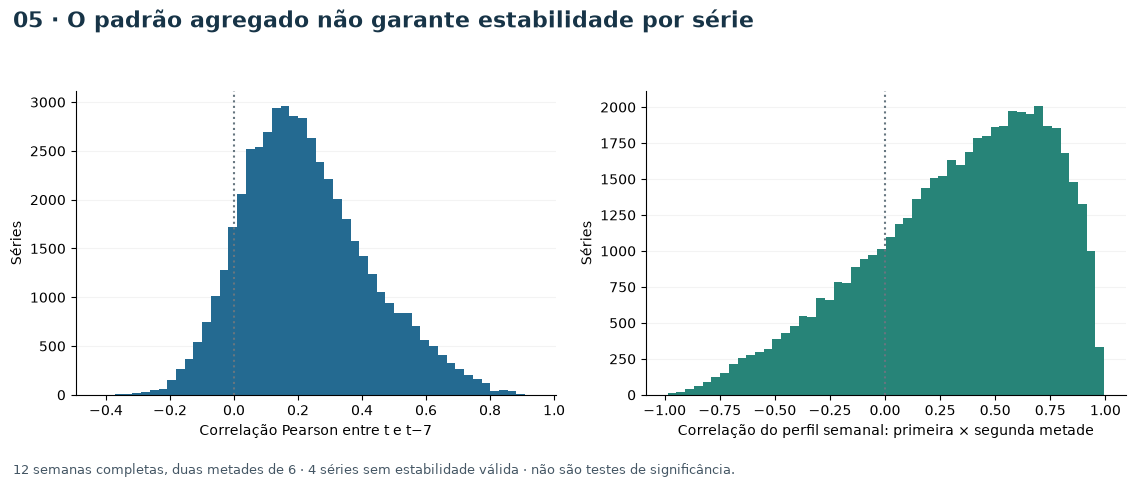

In [6]:
fig = PLOTS[4](data)
save_figure(fig, 5, root)
display(fig)
plt.close(fig)

## 06. Exposição à ruptura

A janela do contador é [06h,22h). Frequência e duração devem acompanhar qualquer leitura de venda observada.

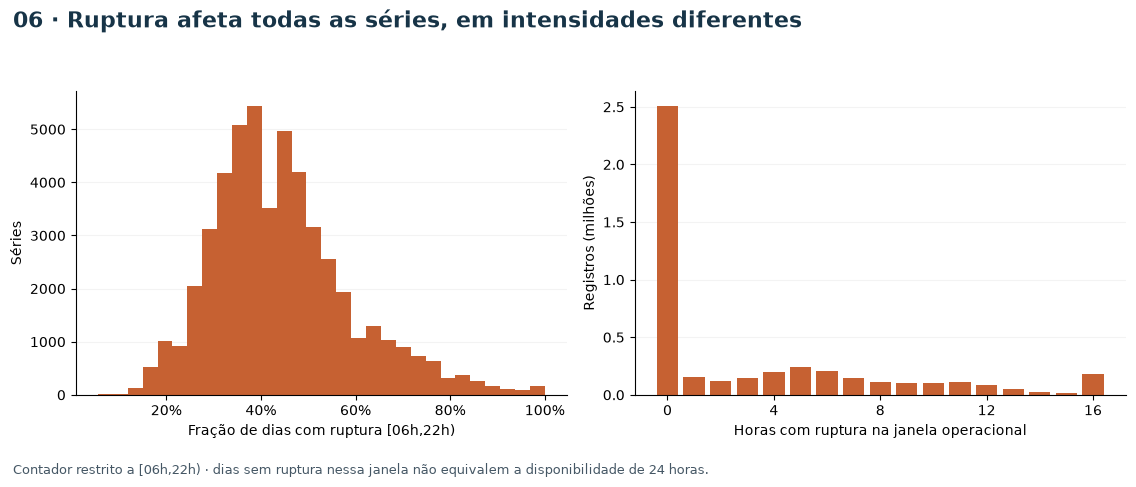

In [7]:
fig = PLOTS[5](data)
save_figure(fig, 6, root)
display(fig)
plt.close(fig)

## 07. Ruptura dentro das séries

A diagonal indica igualdade das médias. Cada célula agrega séries; não há amostragem visual. No outro painel, 16 horas de ruptura concentram zeros.

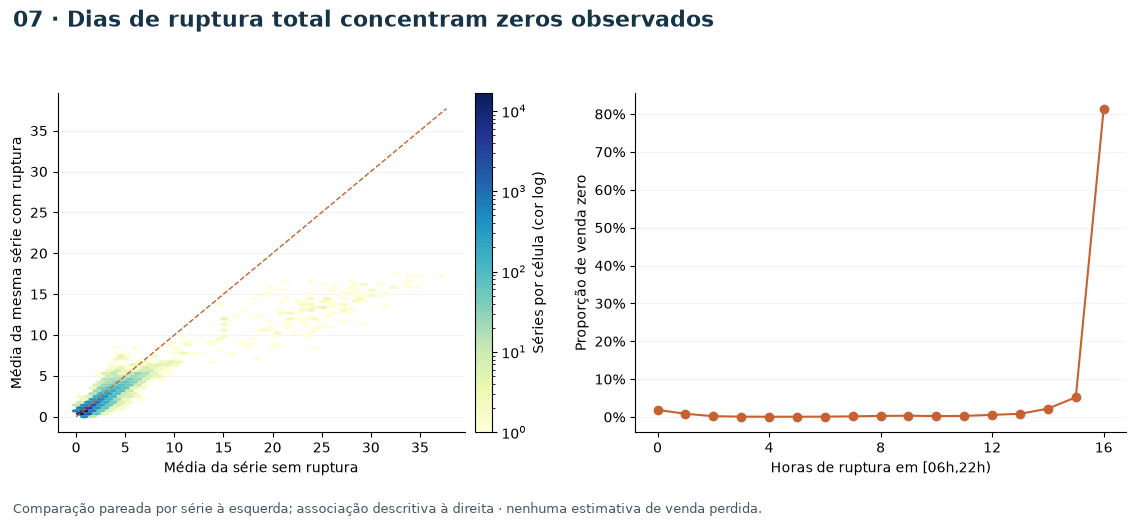

In [8]:
fig = PLOTS[6](data)
save_figure(fig, 7, root)
display(fig)
plt.close(fig)

## 08. Atividade e desconto

A comparação é dentro da série, mas não controla calendário ou seleção da promoção. Os 34 discount > 1 permanecem nos dados; a listagem completa está no relatório.

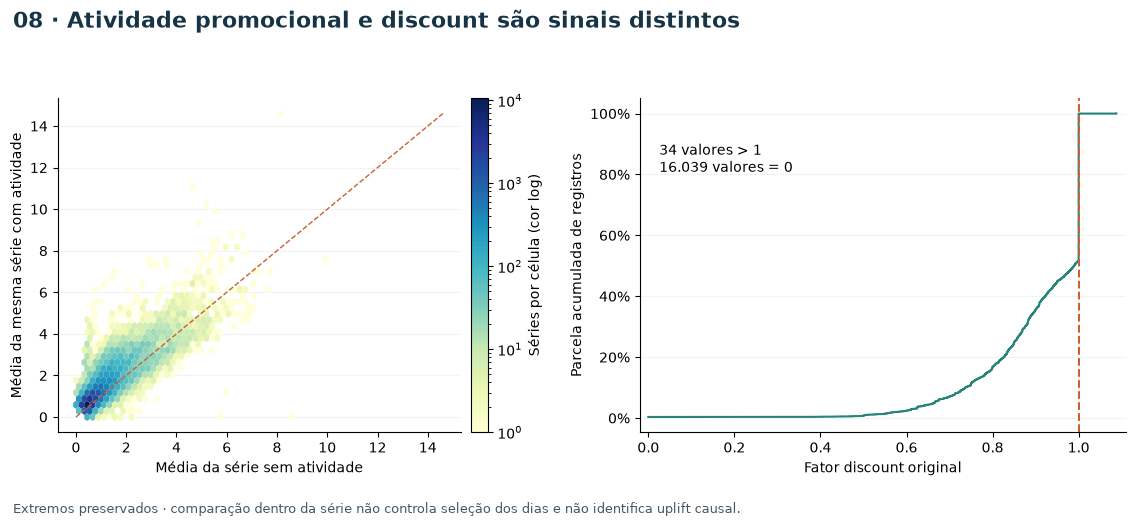

In [9]:
fig = PLOTS[7](data)
save_figure(fig, 8, root)
display(fig)
plt.close(fig)

## 09. Exemplos reproduzíveis

Filtros p25/p75 de train e extremos de CV/zeros; desempate por loja e produto. Regras e identificadores estão em summary.json, sem escolha manual.

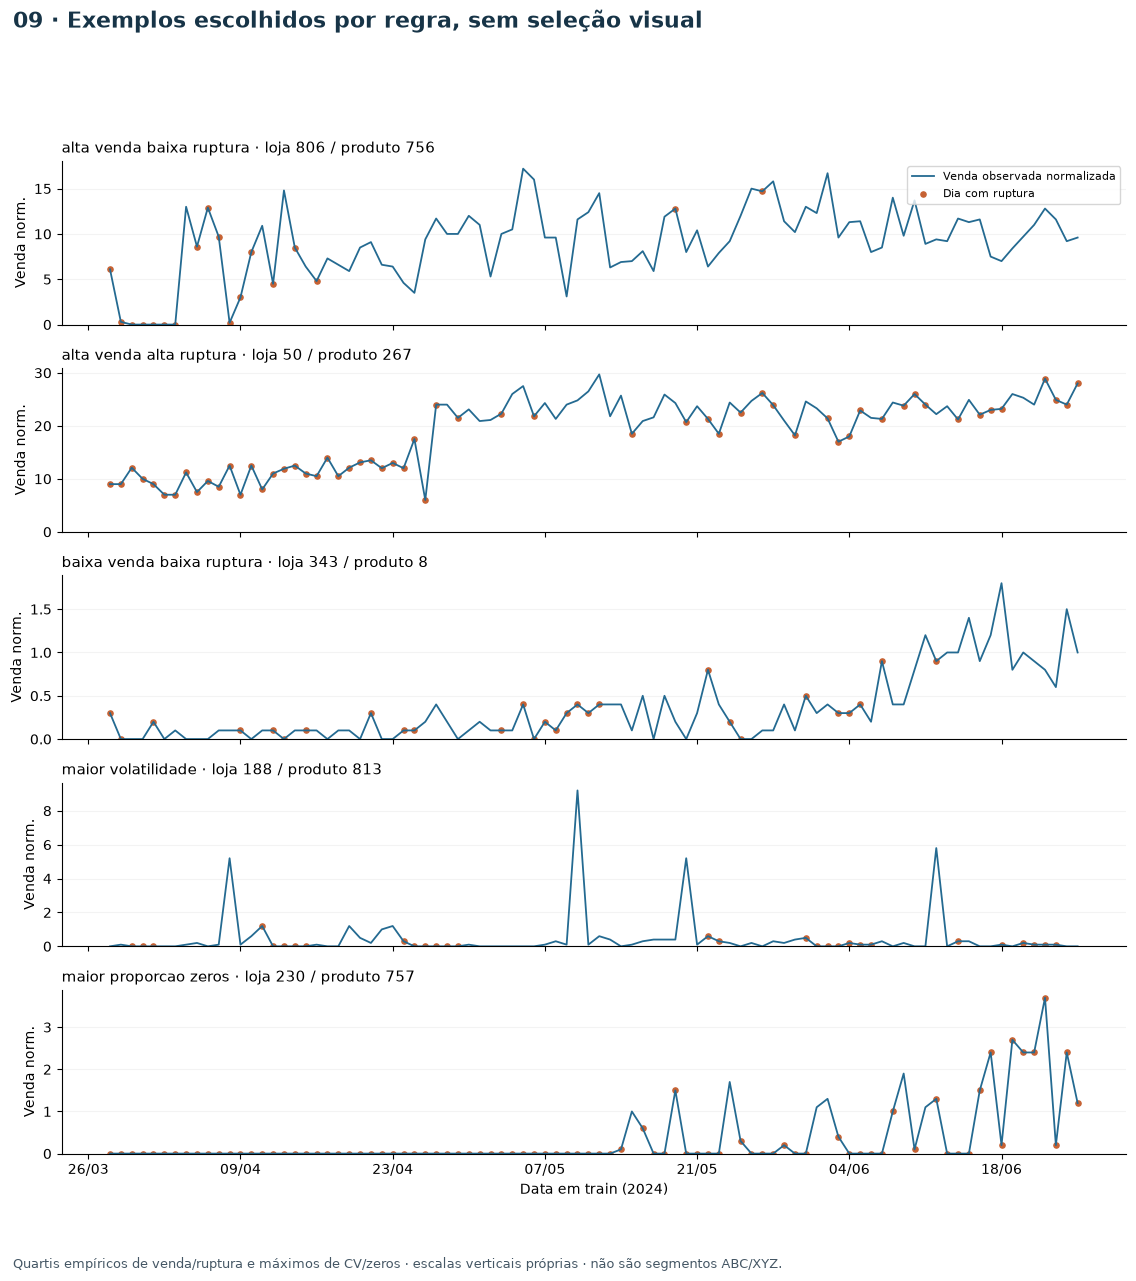

In [10]:
fig = PLOTS[8](data)
save_figure(fig, 9, root)
display(fig)
plt.close(fig)